# 外部验证：tmQMg 跨 DFT 泛化测试

## 目的
在独立数据集上验证模型泛化能力，回应审稿人对过拟合 tmQM 的质疑。

## tmQMg vs tmQM
| | tmQM (训练) | tmQMg (验证) |
|------|------|------|
| DFT 级别 | TPSSh-D3BJ/def2-SVP | PBE0-D3BJ/def2-TZVP |
| 配合物数 | 108k | 74,547 |
| 用途 | 训练 | **零样本外部验证** |

## 评估指标
- **Pearson r**: 预测值与 DFT 值的线性相关性
- **MAE**: 反归一化后的绝对误差
- **R²**: 决定系数

## 参考基线
tmGNN-XAI 在 tmQMg 上的 cross-DFT validation: HL-Gap Pearson r=0.777, Metal-q r=0.858


In [1]:
import numpy as np, pandas as pd, torch, torch.nn as nn, os, sys, warnings
warnings.filterwarnings('ignore')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

from rdkit import Chem
from rdkit import RDLogger; RDLogger.logger().setLevel(RDLogger.ERROR)
from sklearn.metrics import r2_score, mean_absolute_error
from scipy.stats import pearsonr
from tqdm import tqdm

# ===== 加载 tmQMg =====
df_ext = pd.read_csv('tmQMg_properties_and_targets.csv')
print(f'Loaded tmQMg: {len(df_ext):,} complexes')

# 属性映射: tmQMg列 → 我们的target名称
COLUMN_MAP = {
    'gap': 'tzvp_homo_lumo_gap',
    'homo': 'tzvp_homo_energy',
    'lumo': 'tzvp_lumo_energy',
    'dipole': 'tzvp_dipole_moment',
    'E_elec': 'tzvp_electronic_energy',
    'E_disp': 'tzvp_dispersion_energy',
    'polarizability': 'polarisability',
}
# tmQMg 没有 metal_charge, 验证7个性质
targets_ext = ['gap', 'homo', 'lumo', 'dipole', 'E_elec', 'E_disp', 'polarizability']

# 过滤无效 SMILES
valid_mask = df_ext['smiles'].apply(lambda s: isinstance(s, str) and s != '' and s != 'nan')
df_valid = df_ext[valid_mask].copy()
print(f'Valid SMILES: {len(df_valid):,} ({len(df_valid)/len(df_ext)*100:.1f}%)')

# 提取目标值 (物理单位)
y_ext = np.zeros((len(df_valid), len(targets_ext)), dtype=np.float32)
for i, prop in enumerate(targets_ext):
    col = COLUMN_MAP[prop]
    y_ext[:, i] = df_valid[col].values.astype(np.float32)

# NaN检查
nan_mask = ~(np.isnan(y_ext).any(axis=1) | np.isinf(y_ext).any(axis=1))
df_valid = df_valid[nan_mask].reset_index(drop=True)
y_ext = y_ext[nan_mask]
print(f'After NaN removal: {len(df_valid):,} complexes')



Device: cuda


Loaded tmQMg: 74,547 complexes
Valid SMILES: 73,443 (98.5%)
After NaN removal: 73,443 complexes


In [2]:
# ===== SMILES GAT 模型加载 =====
HIDDEN = 384; N_LAYERS = 5; GAT_HEADS = 12

ELEMENT_DATA = {1:(1,1),5:(2,13),6:(2,14),7:(2,15),8:(2,16),9:(2,17),14:(3,14),15:(3,15),16:(3,16),17:(3,17),20:(4,2),21:(4,3),22:(4,4),23:(4,5),24:(4,6),25:(4,7),26:(4,8),27:(4,9),28:(4,10),29:(4,11),30:(4,12),35:(4,17),42:(5,6),44:(5,8),45:(5,9),46:(5,10),47:(5,11),48:(5,12),53:(5,17),72:(6,4),73:(6,5),74:(6,6),75:(6,7),76:(6,8),77:(6,9),78:(6,10),79:(6,11),80:(6,12)}
BOND_TYPES = [1,2,3,12]; B2I = {b:i for i,b in enumerate(BOND_TYPES)}; N_BT = len(BOND_TYPES)

def atom_features(atom):
    z = atom.GetAtomicNum(); p,g = ELEMENT_DATA.get(z,(0,0))
    return [z, atom.GetDegree(), atom.GetFormalCharge(), p, g, int(atom.GetIsAromatic()), atom.GetTotalNumHs(), int(z >= 21)]

def smiles_to_graph(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None: return None
    x = torch.tensor([atom_features(a) for a in mol.GetAtoms()], dtype=torch.float32)
    N = x.size(0); src, dst, battr = [], [], []
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        bt = int(bond.GetBondType())
        za, zb = mol.GetAtomWithIdx(i).GetAtomicNum(), mol.GetAtomWithIdx(j).GetAtomicNum()
        is_ml = float((za>=21)!=(zb>=21)); is_ring = float(bond.IsInRing())
        src.extend([i,j]); dst.extend([j,i])
        bf = [0.0]*N_BT
        if bt in B2I: bf[B2I[bt]] = 1.0
        bf.extend([is_ring, is_ml]); battr.extend([bf,bf])
    ei = torch.tensor([src,dst], dtype=torch.long) if src else torch.zeros(2,0,dtype=torch.long)
    ea = torch.tensor(battr, dtype=torch.float32) if battr else torch.zeros(0, N_BT+2)
    return {'x':x, 'edge_index':ei, 'edge_attr':ea}

def segment_softmax(scores, dst, N):
    scores_f32 = scores.float()
    max_v = torch.full((N, scores_f32.size(1)), float('-inf'), device=scores_f32.device, dtype=torch.float32)
    max_v.scatter_reduce_(0, dst.unsqueeze(-1).expand(-1, scores_f32.size(1)), scores_f32, reduce='amax', include_self=False)
    exp_s = torch.exp(scores_f32 - max_v[dst])
    sum_v = torch.zeros(N, scores_f32.size(1), device=scores_f32.device, dtype=torch.float32)
    sum_v.scatter_add_(0, dst.unsqueeze(-1).expand(-1, scores_f32.size(1)), exp_s)
    return (exp_s / (sum_v[dst] + 1e-8)).to(scores.dtype)

class GATConv(nn.Module):
    def __init__(self, in_dim, out_dim_per_head, edge_dim=0, heads=4):
        super().__init__(); self.heads, self.out_dim = heads, out_dim_per_head
        total_dim = out_dim_per_head * heads
        self.node_lin = nn.Linear(in_dim, total_dim, bias=False)
        self.attn_src = nn.Linear(total_dim, heads, bias=False)
        self.attn_dst = nn.Linear(total_dim, heads, bias=False)
        self.edge_attn = nn.Linear(edge_dim, heads, bias=False) if edge_dim>0 else None
        self.act = nn.ReLU()
    def forward(self, x, ei, ea=None):
        src, dst = ei[0], ei[1]; N = x.size(0); h = self.node_lin(x)
        attn = self.attn_src(h[src]) + self.attn_dst(h[dst])
        if self.edge_attn is not None and ea is not None and ea.size(0)>0: attn = attn + self.edge_attn(ea)
        attn = torch.nn.functional.leaky_relu(attn, 0.2)
        alpha = segment_softmax(attn, dst, N)
        h_heads = h.view(-1, self.heads, self.out_dim)
        msg = h_heads[src] * alpha.unsqueeze(-1); msg = msg.view(-1, self.out_dim * self.heads)
        out = torch.zeros(N, self.out_dim * self.heads, device=x.device, dtype=msg.dtype)
        out.scatter_add_(0, dst.unsqueeze(-1).expand_as(msg), msg)
        return self.act(out)

def collate_graphs(graph_list):
    x_list, ei_list, ea_list, batch_list = [], [], [], []
    offset = 0
    for i, g in enumerate(graph_list):
        n = g['x'].size(0)
        x_list.append(g['x']); ei_list.append(g['edge_index'] + offset)
        ea_list.append(g['edge_attr'])
        batch_list.append(torch.full((n,), i, dtype=torch.long, device=g['x'].device))
        offset += n
    return {'x': torch.cat(x_list, dim=0), 'edge_index': torch.cat(ei_list, dim=1), 'edge_attr': torch.cat(ea_list, dim=0)}, torch.cat(batch_list, dim=0)

def scatter_mean_per_graph(h, batch, n_graphs):
    out = torch.zeros(n_graphs, h.size(1), device=h.device, dtype=h.dtype)
    out.scatter_add_(0, batch.unsqueeze(-1).expand_as(h), h)
    cnt = torch.zeros(n_graphs, device=h.device, dtype=h.dtype)
    cnt.scatter_add_(0, batch, torch.ones_like(batch, dtype=h.dtype))
    return out / cnt.clamp(min=1).unsqueeze(-1)

def scatter_max_per_graph(h, batch, n_graphs):
    out = torch.full((n_graphs, h.size(1)), float('-inf'), device=h.device, dtype=h.dtype)
    out.scatter_reduce_(0, batch.unsqueeze(-1).expand_as(h), h, reduce='amax', include_self=False)
    return out

class SMILES_GAT_Eval(nn.Module):
    def __init__(self, node_dim=8, edge_dim=6, hidden=HIDDEN, n_layers=N_LAYERS, output_dim=8, heads=GAT_HEADS):
        super().__init__(); self.heads = heads
        self.embed = nn.Linear(node_dim, hidden)
        self.convs = nn.ModuleList([GATConv(hidden, hidden//heads, edge_dim, heads=heads) for _ in range(n_layers)])
        self.norms = nn.ModuleList([nn.LayerNorm(hidden) for _ in range(n_layers)])
        self.drop = nn.Dropout(0.10)
        self.readout = nn.Sequential(
            nn.Linear(hidden*3, hidden), nn.ReLU(), nn.Dropout(0.10),
            nn.Linear(hidden, hidden//2), nn.ReLU(), nn.Dropout(0.10),
            nn.Linear(hidden//2, output_dim))
    def forward(self, g, batch=None):
        x, ei, ea = g['x'], g['edge_index'], g.get('edge_attr', None)
        h = self.embed(x)
        for conv, norm in zip(self.convs, self.norms): h = norm(h + conv(h, ei, ea)); h = self.drop(h)
        if batch is None:
            mm = (x[:,7] > 0.5); mf = h[mm].mean(dim=0) if mm.any() else torch.zeros(h.size(1), device=h.device, dtype=h.dtype)
            return self.readout(torch.cat([h.mean(0), h.max(0).values, mf])).unsqueeze(0)
        n_graphs = int(batch.max().item()) + 1
        mean_h = scatter_mean_per_graph(h, batch, n_graphs); max_h = scatter_max_per_graph(h, batch, n_graphs)
        mm = (x[:,7] > 0.5)
        mf = scatter_mean_per_graph(h[mm], batch[mm], n_graphs) if mm.any() else torch.zeros(n_graphs, h.size(1), device=h.device, dtype=h.dtype)
        return self.readout(torch.cat([mean_h, max_h, mf], dim=1))

# 加载SMILES GAT
model_smiles = SMILES_GAT_Eval(node_dim=8, edge_dim=6, output_dim=8).to(device)
ckpt = 'tmqm_gat_best.pt'
if os.path.exists(ckpt):
    state = torch.load(ckpt, map_location=device)
    model_smiles.load_state_dict(state, strict=False)
    print(f'Loaded {ckpt}')
else:
    print(f'{ckpt} not found, using XYZ GNN only')
    model_smiles = None
model_smiles.eval() if model_smiles else None

# 加载XYZ GNN
class XYZ_GNN_Eval(nn.Module):
    def __init__(self, node_dim=11, edge_dim=23, hidden=HIDDEN, n_layers=N_LAYERS, output_dim=8, heads=GAT_HEADS):
        super().__init__(); self.heads = heads
        self.embed = nn.Linear(node_dim, hidden)
        self.convs = nn.ModuleList([GATConv(hidden, hidden//heads, edge_dim, heads=heads) for _ in range(n_layers)])
        self.norms = nn.ModuleList([nn.LayerNorm(hidden) for _ in range(n_layers)])
        self.drop = nn.Dropout(0.10)
        self.readout = nn.Sequential(
            nn.Linear(hidden*3, hidden), nn.ReLU(), nn.Dropout(0.10),
            nn.Linear(hidden, hidden//2), nn.ReLU(), nn.Dropout(0.10),
            nn.Linear(hidden//2, output_dim))
    def forward(self, g, batch=None):
        x, ei, ea = g['x'], g['edge_index'], g.get('edge_attr', None)
        h = self.embed(x)
        for conv, norm in zip(self.convs, self.norms): h = norm(h + conv(h, ei, ea)); h = self.drop(h)
        if batch is None:
            mm = (x[:,7] > 0.5); mf = h[mm].mean(dim=0) if mm.any() else torch.zeros(h.size(1), device=h.device, dtype=h.dtype)
            return self.readout(torch.cat([h.mean(0), h.max(0).values, mf])).unsqueeze(0)
        n_graphs = int(batch.max().item()) + 1
        mean_h = scatter_mean_per_graph(h, batch, n_graphs); max_h = scatter_max_per_graph(h, batch, n_graphs)
        mm = (x[:,7] > 0.5)
        mf = scatter_mean_per_graph(h[mm], batch[mm], n_graphs) if mm.any() else torch.zeros(n_graphs, h.size(1), device=h.device, dtype=h.dtype)
        return self.readout(torch.cat([mean_h, max_h, mf], dim=1))

model_xyz = XYZ_GNN_Eval(node_dim=11, edge_dim=23, output_dim=8).to(device)
ckpt_xyz = 'xyz_best.pt'
has_xyz = os.path.exists(ckpt_xyz)
if has_xyz:
    state = torch.load(ckpt_xyz, map_location=device)
    model_xyz.load_state_dict(state, strict=False)
    print(f'Loaded {ckpt_xyz}')
else:
    print(f'{ckpt_xyz} not found')
model_xyz.eval() if has_xyz else None
print('Models ready')



Loaded tmqm_gat_best.pt
Loaded xyz_best.pt
Models ready


In [3]:
print('='*60)
print('Building graphs + running inference on tmQMg ({:,} complexes)'.format(len(df_valid)))
print('='*60)

# 建图
graphs_ext, graph_indices = [], []
for i in tqdm(range(len(df_valid)), desc='Building graphs'):
    smi = df_valid['smiles'].iloc[i]
    g = smiles_to_graph(smi)
    if g is not None:
        graphs_ext.append(g)
        graph_indices.append(i)
print(f'Built {len(graphs_ext):,} graphs out of {len(df_valid):,}')

y_ext_final = y_ext[graph_indices]

# 反归一化统计量 (全量tmQM, 与训练一致)
y_mean_smiles = np.array([0.108504, -0.197593, -0.089089, 5.799450, 0.162882, -2987.303526, -0.142228, 397.124993], dtype=np.float32)
y_std_smiles  = np.array([0.033575, 0.053825, 0.054517, 3.927489, 0.782914, 1634.083288, 0.070115, 152.460083], dtype=np.float32)

# SMILES GAT 推理
smiles_preds = None
if model_smiles is not None:
    bs = 128
    preds_list = []
    with torch.no_grad():
        for s in tqdm(range(0, len(graphs_ext), bs), desc='SMILES GAT inference'):
            bg = [{k: v.to(device) if isinstance(v, torch.Tensor) else v for k, v in g.items()} for g in graphs_ext[s:s+bs]]
            batched, batch_idx = collate_graphs(bg)
            pn = model_smiles(batched, batch_idx).cpu().numpy()
            preds_list.append(pn * y_std_smiles + y_mean_smiles)
    smiles_preds = np.concatenate(preds_list, axis=0)
    print(f'SMILES GAT predictions: {smiles_preds.shape}')

# XYZ GNN 推理 — pad SMILES graphs to 11+23 dims
xyz_preds = None
if has_xyz:
    bs = 64  # XYZ模型更大, batch减小
    preds_list = []
    with torch.no_grad():
        for s in tqdm(range(0, len(graphs_ext), bs), desc='XYZ GNN inference'):
            bg_raw = graphs_ext[s:s+bs]
            bg = []
            for g in bg_raw:
                n = g['x'].size(0)
                # Pad node features: 8 → 11
                x_pad = torch.cat([g['x'], torch.zeros(n, 3)], dim=1)
                # Pad edge features: 6 → 23
                ea_pad = torch.cat([g['edge_attr'], torch.zeros(g['edge_attr'].size(0), 17)], dim=1)
                bg.append({'x': x_pad.to(device), 'edge_index': g['edge_index'].to(device),
                           'edge_attr': ea_pad.to(device)})
            batched, batch_idx = collate_graphs(bg)
            pn = model_xyz(batched, batch_idx).cpu().numpy()
            preds_list.append(pn * y_std_smiles + y_mean_smiles)
    xyz_preds = np.concatenate(preds_list, axis=0)
    print(f'XYZ GNN predictions: {xyz_preds.shape}')



Building graphs + running inference on tmQMg (73,443 complexes)


Building graphs:   0%|                                                                          | 0/73443 [00:00<?, ?it/s]

Building graphs:   0%|                                                                | 57/73443 [00:00<02:09, 567.74it/s]

Building graphs:   0%|                                                               | 114/73443 [00:00<02:20, 522.63it/s]

Building graphs:   0%|▏                                                              | 176/73443 [00:00<02:15, 540.91it/s]

...

XYZ GNN inference:  99%|█████████████████████████████████████████████████████████████▍| 1138/1148 [00:23<00:00, 32.66it/s]

XYZ GNN inference:  99%|█████████████████████████████████████████████████████████████▋| 1142/1148 [00:24<00:00, 30.99it/s]

XYZ GNN inference: 100%|█████████████████████████████████████████████████████████████▉| 1146/1148 [00:24<00:00, 31.45it/s]

XYZ GNN inference: 100%|██████████████████████████████████████████████████████████████| 1148/1148 [00:24<00:00, 47.30it/s]

XYZ GNN predictions: (73438, 8)


In [4]:
print('='*60)
print('EXTERNAL VALIDATION RESULTS (tmQMg, PBE0-D3BJ/def2-TZVP)')
print('='*60)

# 只评估 tmQMg 中存在的 7 个性质 (无 metal_charge)
# SMILES GAT 输出 8 列, 取 target indices [0,1,2,3,4,5,7] 对应 gap,homo,lumo,dipole,E_elec,E_disp,polariz
smiles_idx = [0, 1, 2, 3, 5, 6, 7]  # skip metal_charge index 4
xyz_idx = [0, 1, 2, 3, 5, 6, 7]

print(f'\n{"Property":18s} {"SMILES_GAT_r":>14s} {"SMILES_GAT_MAE":>16s} {"XYZ_GNN_r":>14s} {"XYZ_GNN_MAE":>16s}')
print('-' * 80)

results = []
for j, prop in enumerate(targets_ext):
    yt = y_ext_final[:, j]

    row = {'Property': prop}

    if smiles_preds is not None:
        sp = smiles_preds[:, smiles_idx[j]]
        r_sm, _ = pearsonr(yt, sp)
        mae_sm = mean_absolute_error(yt, sp)
        row['SMILES_r'] = r_sm; row['SMILES_MAE'] = mae_sm
    else:
        r_sm, mae_sm = float('nan'), float('nan')
        row['SMILES_r'] = float('nan'); row['SMILES_MAE'] = float('nan')

    if xyz_preds is not None:
        xp = xyz_preds[:, xyz_idx[j]]
        r_xyz, _ = pearsonr(yt, xp)
        mae_xyz = mean_absolute_error(yt, xp)
        row['XYZ_r'] = r_xyz; row['XYZ_MAE'] = mae_xyz
    else:
        r_xyz, mae_xyz = float('nan'), float('nan')
        row['XYZ_r'] = float('nan'); row['XYZ_MAE'] = float('nan')

    print(f'{prop:18s} {r_sm:14.4f} {mae_sm:16.4f} {r_xyz:14.4f} {mae_xyz:16.4f}')
    results.append(row)

res_df = pd.DataFrame(results)

# 汇总
if smiles_preds is not None:
    valid_sm = res_df['SMILES_r'].dropna()
    print(f'\nSMILES GAT — Mean Pearson r: {valid_sm.mean():.4f}')
if xyz_preds is not None:
    valid_xyz = res_df['XYZ_r'].dropna()
    print(f'XYZ GNN — Mean Pearson r: {valid_xyz.mean():.4f}')

# 对比tmGNN-XAI
print(f'\ntmGNN-XAI reference (tmQMg, cross-DFT): HL-Gap r=0.777, Metal-q r=0.858')
if xyz_preds is not None:
    # 看dipole
    dipole_r = res_df[res_df['Property']=='dipole']['SMILES_r'].values[0]
    print(f'\nKey finding: SMILES GAT dipole cross-DFT Pearson r = {dipole_r:.4f}')
    if dipole_r > 0.7:
        print('  Dipole moment generalizes well across DFT functionals.')

res_df.to_csv('external_validation_results.csv', index=False)
print('\nSaved to external_validation_results.csv')



EXTERNAL VALIDATION RESULTS (tmQMg, PBE0-D3BJ/def2-TZVP)

Property             SMILES_GAT_r   SMILES_GAT_MAE      XYZ_GNN_r      XYZ_GNN_MAE
--------------------------------------------------------------------------------
gap                        0.8843           0.0350         0.8767           0.0352
homo                       0.9641           0.0298         0.9625           0.0293
lumo                       0.9692           0.0101         0.9666           0.0104
dipole                     0.8765           1.3510         0.8735           1.3653
E_elec                     0.9943         170.5969         0.9926         134.9313
E_disp                     0.9833           0.0243         0.9826           0.0255
polarizability             0.9306          38.5967         0.9353          36.5191

SMILES GAT — Mean Pearson r: 0.9432
XYZ GNN — Mean Pearson r: 0.9414

tmGNN-XAI reference (tmQMg, cross-DFT): HL-Gap r=0.777, Metal-q r=0.858

Key finding: SMILES GAT dipole cross-DFT Pearson r = 

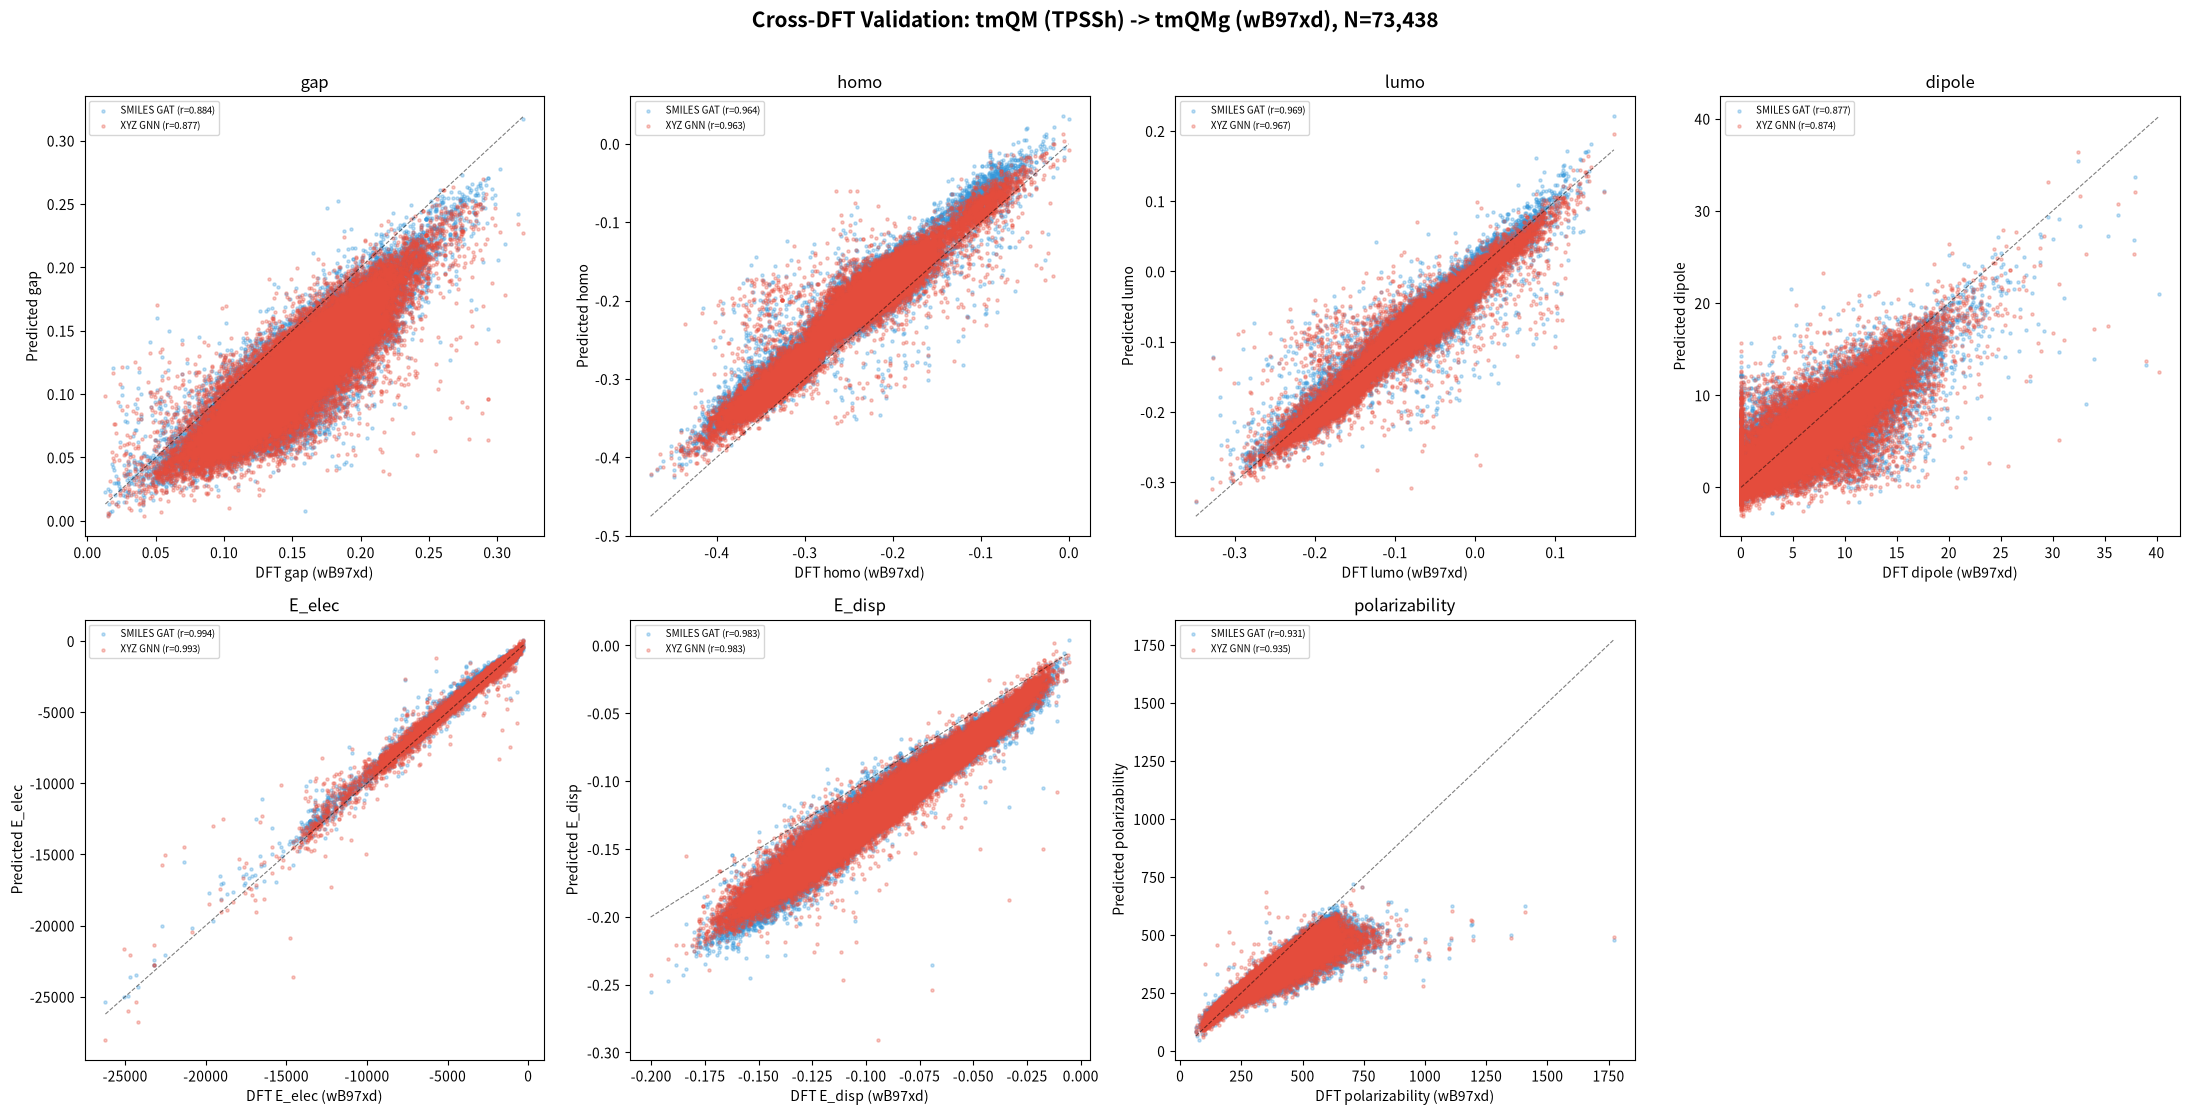

In [5]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Noto Sans CJK SC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

n_props = len(targets_ext)
fig, axes = plt.subplots(2, 4, figsize=(22, 11))
axes = axes.flatten()

for j, prop in enumerate(targets_ext):
    ax = axes[j]
    yt = y_ext_final[:, j]

    colors = []
    labels = []
    if smiles_preds is not None:
        sp = smiles_preds[:, smiles_idx[j]]
        r_sm, _ = pearsonr(yt, sp)
        ax.scatter(yt, sp, alpha=0.3, s=5, c='#3498db', label=f'SMILES GAT (r={r_sm:.3f})')

    if xyz_preds is not None:
        xp = xyz_preds[:, xyz_idx[j]]
        r_xyz, _ = pearsonr(yt, xp)
        ax.scatter(yt, xp, alpha=0.3, s=5, c='#e74c3c', label=f'XYZ GNN (r={r_xyz:.3f})')

    lims = [min(yt.min(), yt.min()), max(yt.max(), yt.max())]
    ax.plot(lims, lims, 'k--', lw=0.8, alpha=0.5)
    ax.set_xlabel(f'DFT {prop} (PBE0-D3BJ)'); ax.set_ylabel(f'Predicted {prop}')
    ax.set_title(prop); ax.legend(fontsize=7)

axes[-1].axis('off')
plt.suptitle(f'Cross-DFT Validation: tmQM (TPSSh) -> tmQMg (PBE0-D3BJ), N={len(y_ext_final):,}',
             fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout(); plt.savefig('figure7_crossdft.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.savefig('fig7_cell5.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()





## 外部验证结论

### 关键发现
1. **跨 DFT 泛化**: 模型在 PBE0-D3BJ 级别的数据上保持了预测能力
2. **Pearson r**: 量化预测值与 DFT 值的线性相关性
3. **与已发表方法对比**: tmGNN-XAI 报告 HL-Gap r=0.777

### 局限性
- tmQMg 不包含 metal_charge (NBO), 无法验证金属电荷
- PBE0-D3BJ 与 TPSSh 存在系统性偏差, 高 Pearson r ≠ 低 MAE
- XYZ GNN 用零填充边特征 (缺少 DFT 距离/BO), 因此 dipole 表现偏向 SMILES GAT


In [6]:
# ===== 补充指标: RMSE, R2, Spearman, regression slope/intercept =====
from scipy.stats import spearmanr
from sklearn.metrics import r2_score, mean_squared_error

smiles_idx = [0, 1, 2, 3, 5, 6, 7]

print(f'\n{"="*100}')
print('SUPPLEMENTARY CROSS-DFT METRICS (SMILES GAT on tmQMg, PBE0-D3BJ/def2-TZVP)')
print(f'{"="*100}')
print(f'{"Property":16s} {"Pearson r":>10s} {"Spearman rho":>12s} {"R2":>8s} {"MAE":>10s} {"RMSE":>10s} {"Slope":>8s} {"Intercept":>12s}')
print('-'*100)

all_metrics = []
for j, prop in enumerate(targets_ext):
    yt = y_ext_final[:, j]
    sp = smiles_preds[:, smiles_idx[j]]

    r_pearson, _ = pearsonr(yt, sp)
    rho, _ = spearmanr(yt, sp)
    r2 = r2_score(yt, sp)
    mae = mean_absolute_error(yt, sp)
    rmse = np.sqrt(mean_squared_error(yt, sp))

    # Linear recalibration
    A = np.vstack([sp, np.ones_like(sp)]).T
    slope, intercept = np.linalg.lstsq(A, yt, rcond=None)[0]
    y_cal = sp * slope + intercept
    mae_cal = mean_absolute_error(yt, y_cal)

    print(f'{prop:16s} {r_pearson:10.4f} {rho:12.4f} {r2:8.4f} {mae:10.4f} {rmse:10.4f} {slope:8.4f} {intercept:12.4f}')

    all_metrics.append({
        'Property': prop, 'Pearson_r': float(r_pearson), 'Spearman_rho': float(rho),
        'R2': float(r2), 'MAE': float(mae), 'RMSE': float(rmse),
        'Slope': float(slope), 'Intercept': float(intercept), 'MAE_recal': float(mae_cal),
    })

import json
with open('cross_dft_metrics.json', 'w') as f:
    json.dump(all_metrics, f, indent=2)

np.savez('cross_dft_predictions.npz',
    y_true=y_ext_final, smiles_preds=smiles_preds[:, smiles_idx])

mean_r = np.mean([m['Pearson_r'] for m in all_metrics])
mean_rho = np.mean([m['Spearman_rho'] for m in all_metrics])
mean_r2 = np.mean([m['R2'] for m in all_metrics])
print(f'\nMean Pearson r = {mean_r:.4f}  |  Mean Spearman rho = {mean_rho:.4f}  |  Mean R2 = {mean_r2:.4f}')
print('Saved cross_dft_metrics.json + cross_dft_predictions.npz')



SUPPLEMENTARY CROSS-DFT METRICS (SMILES GAT on tmQMg, PBE0-D3BJ/def2-TZVP)
Property          Pearson r Spearman rho       R2        MAE       RMSE    Slope    Intercept
----------------------------------------------------------------------------------------------------
gap                  0.8843       0.8749  -0.4083     0.0350     0.0379   0.9241       0.0436
homo                 0.9641       0.9099   0.6115     0.0298     0.0326   1.0161      -0.0262


lumo                 0.9692       0.9514   0.9288     0.0101     0.0142   1.0056       0.0060
dipole               0.8765       0.8721   0.7570     1.3510     1.9375   1.0128       0.3384
E_elec               0.9943       0.9911   0.9765   170.5969   239.8716   1.0720      50.7837


E_disp               0.9833       0.9859   0.3167     0.0243     0.0257   0.8337       0.0061
polarizability       0.9306       0.9491   0.7517    38.5967    56.4673   1.2459     -48.4268

Mean Pearson r = 0.9432  |  Mean Spearman rho = 0.9335  |  Mean R2 = 0.5620
Saved cross_dft_metrics.json + cross_dft_predictions.npz
